<a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
# Read the commit CSV
df = pd.read_csv("smazunda_project_summary.csv", sep=";")

# Rename the five columns 
df.columns = ['project','commit','author','time','message']

# Convert the Unix timestamp to YYYY-MM 
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')

# Display the first five rows
df.head()

,project,commit,author,time,message,Month
0,microsoft_textworld,00011bd91daf73b71f1278d52a35424b176a8807,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1663382841,Rename main branch and references to it.\n,2022-09
1,microsoft_textworld,00640623ba2c422d75e3d23eed92d24876037ade,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1702342627,Update prerelease.yml,2023-12
2,microsoft_textworld,00ab85b380fdde6db258509512eb826255033cfd,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1548422542,Remove Tatsu lines in setup.sh\n,2019-01
3,microsoft_textworld,00d172ad1841d989b13258a9cf50db24dba7b042,Tavian Barnes <tavian.barnes@microsoft.com>,1536673476,chaining: Re-generate actions when branching\n...,2018-09
4,microsoft_textworld,00ebb8099092ec35340b9f17f1434a95237a2c46,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1537400780,DependencyTree now support more than one root ...,2018-09


In [3]:
prj='microsoft_textworld'

# Keep commits of the selected project
df1 = df[df['project']==prj]

# Count the number of commits in each month
df2 = df1.groupby('Month').size().reset_index(name='Commits')

# Store the monthly commit counts
monthly_counts = df2

# Convert the month strings to dates
monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])

# Create every month between the first and last commit.\
full_date_range = pd.DataFrame({
    'time': pd.date_range(
        start=monthly_counts['time'].min(),
        end=monthly_counts['time'].max(),
        freq='MS'
    )
})

# Add months with no commits and fill their counts with zero
monthly_counts = pd.merge(
    full_date_range,
    monthly_counts,
    on='time',
    how='left'
).fillna(0)

# Convert the dates back to YYYY-MM format
monthly_counts['Month'] = monthly_counts['time'].dt.strftime('%Y-%m')

In [4]:
# Get the 10 projects
projects = df['project'].unique()

# Process each project separately
for prj in projects:

    # Keep commits for the current project
    df1 = df[df['project'] == prj]

    # Count commits for each month that contains commits
    df2 = df1.groupby('Month').size().reset_index(name='Commits')

    # Store monthly counts
    monthly_counts = df2

    # Convert month strings to dates
    monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])

    # Create every month from first commit month to the last month
    full_date_range = pd.DataFrame({
        'time': pd.date_range(
            start=monthly_counts['time'].min(),
            end=monthly_counts['time'].max(),
            freq='MS'
        )
    })

    # Add missing months to the timeline
    monthly_counts = pd.merge(
        full_date_range,
        monthly_counts,
        on='time',
        how='left'
    ).fillna(0)

    # Convert the dates back to YYYY-MM
    monthly_counts['Month'] = monthly_counts['time'].dt.strftime('%Y-%m')

    # Make commit counts integers
    monthly_counts['Commits'] = monthly_counts['Commits'].astype(int)

    # Save CSV
    monthly_counts[['Month', 'Commits']].rename(
        columns={'Commits':'#Commits'}
    ).to_csv(
        "smazunda_commits_timeseries_"+prj+".csv",
        sep=";",
        index=False
    )

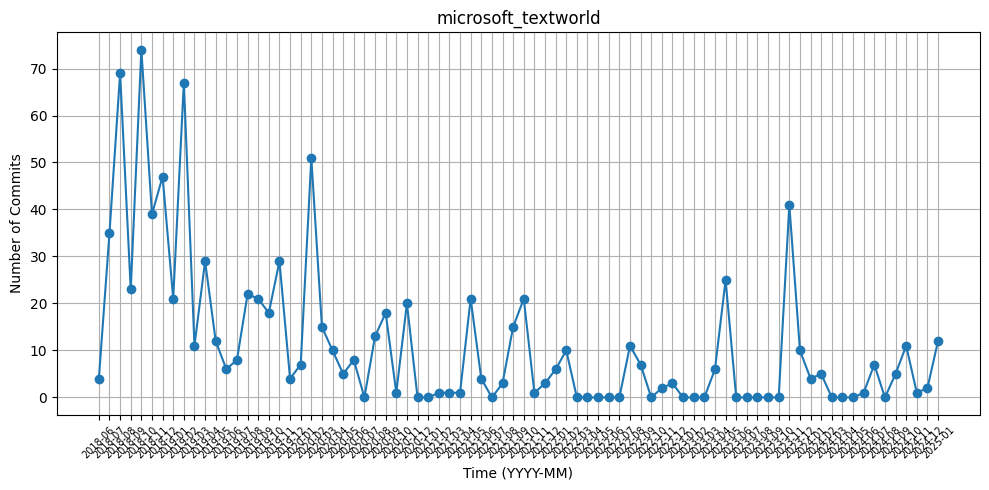

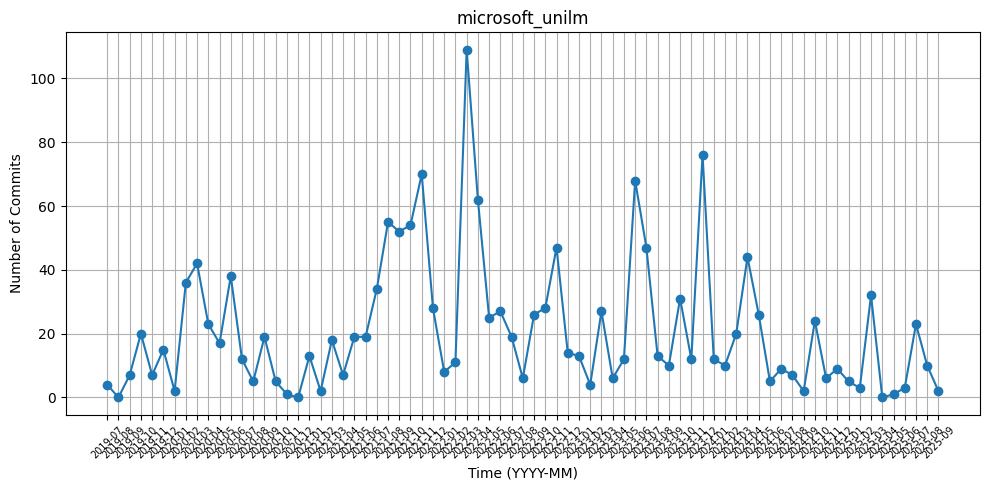

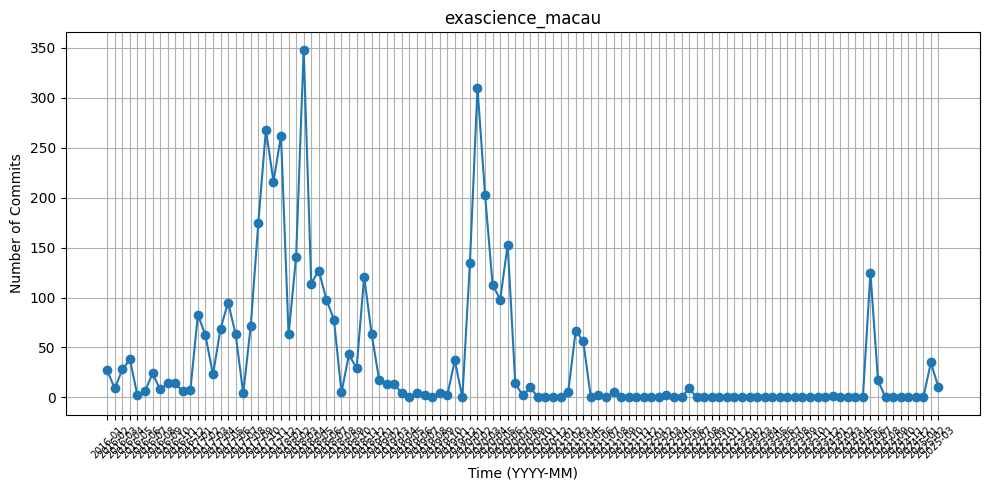

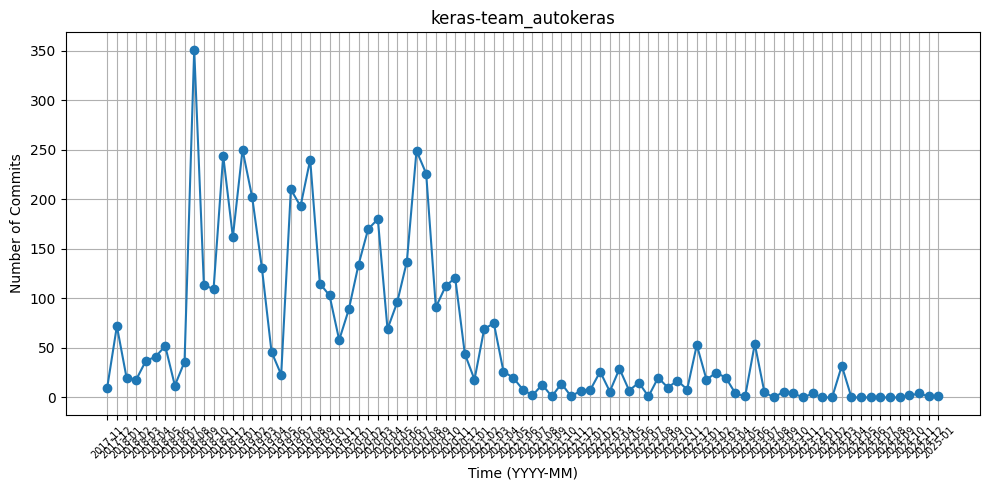

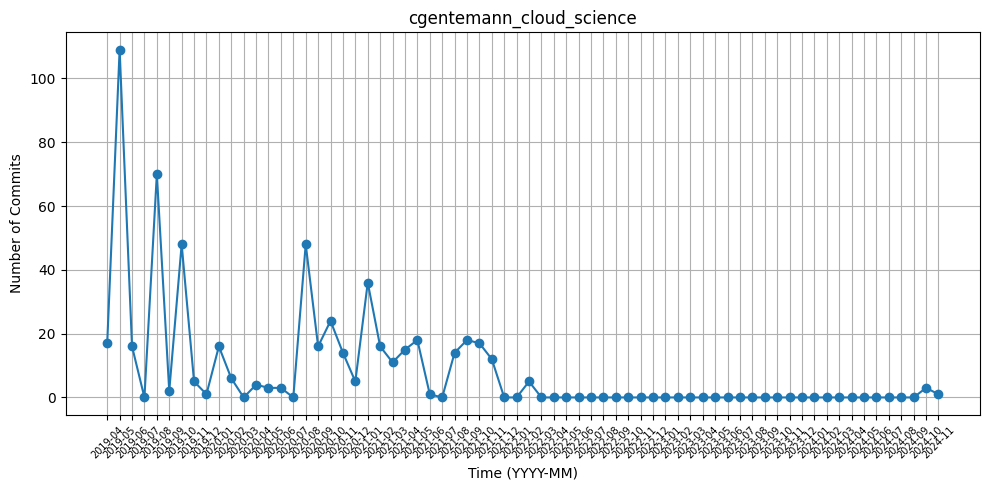

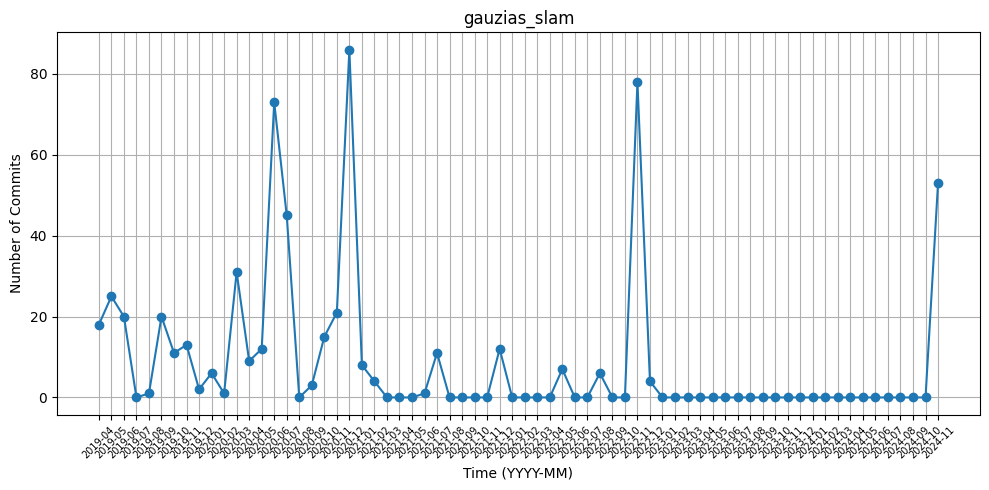

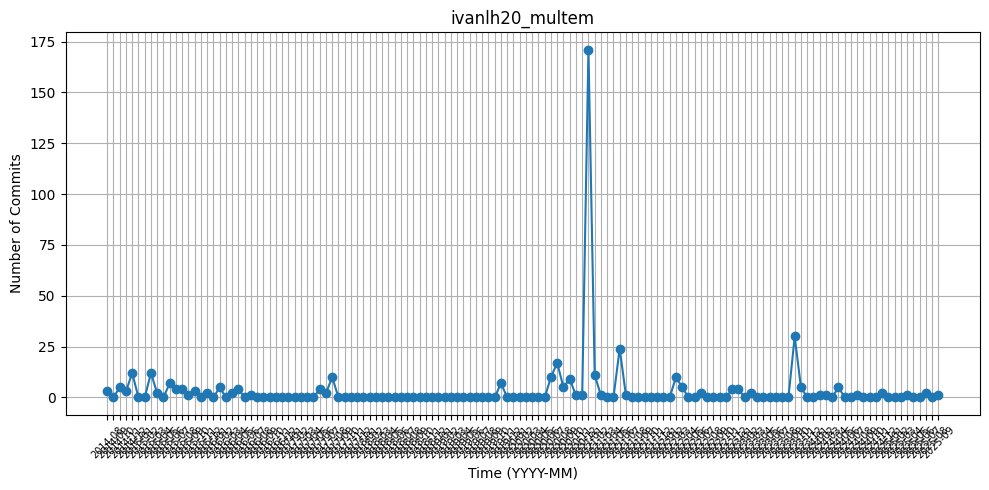

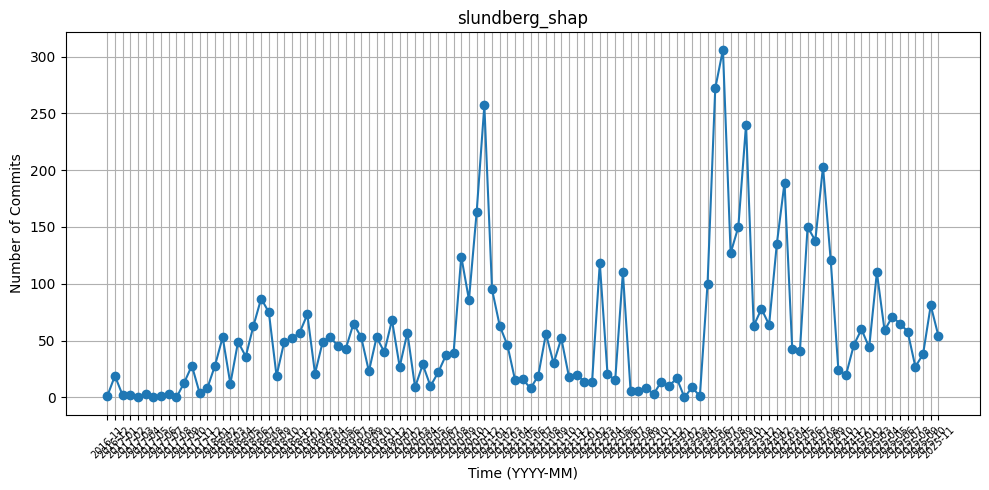

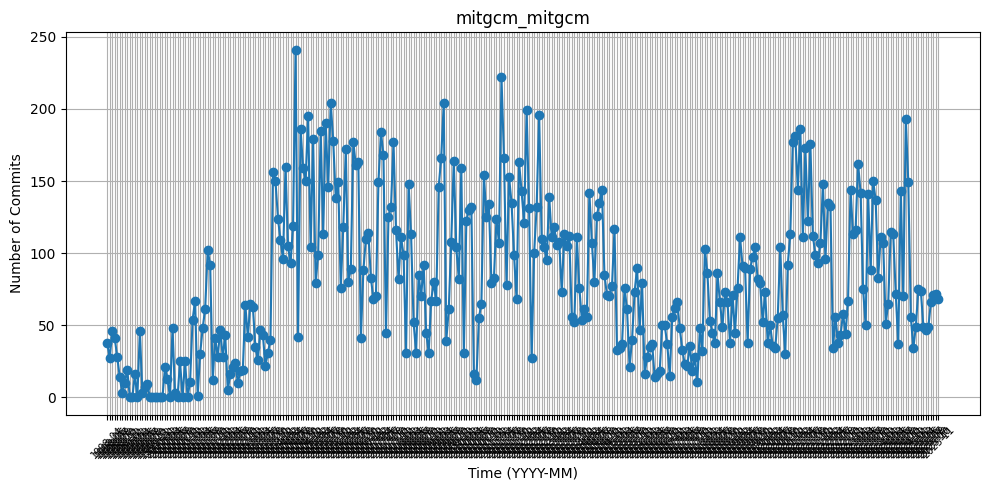

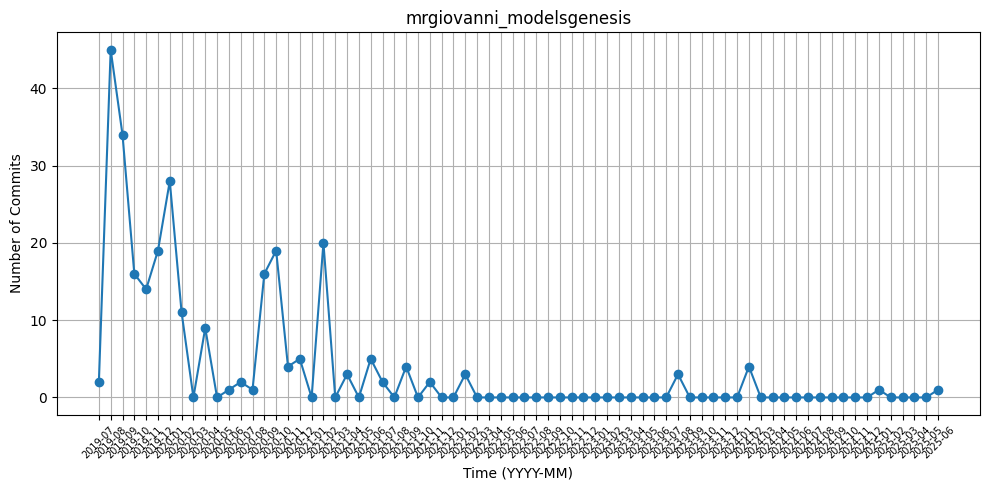

In [5]:
# Create plots for each project
for prj in projects:

    # Read the monthly CSV 
    monthly_counts = pd.read_csv(
        "smazunda_commits_timeseries_"+prj+".csv",
        sep=";"
    )

    # Create the plot
    plt.figure(figsize=(10,5))

    # Plot monthly commit counts
    plt.plot(
        monthly_counts["Month"],
        monthly_counts["#Commits"],
        marker="o",
        linestyle="-"
    )

    # Label x axis
    plt.xlabel("Time (YYYY-MM)")

    # Label y axis
    plt.ylabel("Number of Commits")

    # plot title
    plt.title(prj)

    # grid lines
    plt.grid(True)

    # Rotate the month labels
    plt.xticks(rotation=45, fontsize=7)

    # Adjust the layou
    plt.tight_layout()

    # Save the plot
    plt.savefig(
        "smazunda_timeseries_"+prj+".png",
        dpi=600
    )

    # Display plot
    plt.show()

    # Close the plot before next one
    plt.close()

# Identify the Longest Inactivity Gap

2022-02 to 2023-04

Add all that info to netid_project_stats.csv

In [6]:
# Create a list to store stats of each proj
project_stats = []

# Process each project separately
for prj in projects:

    # Read project's monthly time series
    monthly_counts = pd.read_csv(
        "smazunda_commits_timeseries_"+prj+".csv",
        sep=";"
    )

    # Convert Month column to dates
    monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])

    # Keep only months with zero commits
    zero_months = monthly_counts[
        monthly_counts["#Commits"] == 0
    ].copy()

    # Store all continuous zero-commit gaps
    gaps = []

    # Start with no current gap
    current_start = None

    # Start with no previous month
    previous_month = None

    # Check each zero commit month in order
    for _, row in zero_months.iterrows():

        # Get the current zero commit month
        current_month = row["time"]

        # Start a new gap if this is the first zero month
        if current_start is None:
            current_start = current_month

        # Start a new gap if the current zero month is not consecutive
        elif current_month != previous_month + pd.DateOffset(months=1):
            gaps.append((current_start, previous_month))
            current_start = current_month

        # Remember the current month
        previous_month = current_month

    # Add the final gap if one is still open
    if current_start is not None:
        gaps.append((current_start, previous_month))

    # Store the length of each gap
    gap_info = []

    # Calculate each gap length in months
    for start, end in gaps:

        # Calculate number of months
        length = (
            (end.year - start.year) * 12
            + (end.month - start.month)
            + 1
        )

        # Store the gap information
        gap_info.append({
            "start": start,
            "end": end,
            "length": length
        })

    # Convert the gap information into a DataFrame
    gap_info = pd.DataFrame(gap_info)

    # Check whether at least one zero-commit gap exists
    if len(gap_info) > 0:

        # Select longest gap
        longest_gap = gap_info.loc[
            gap_info["length"].idxmax()
        ]

        # Store longest gap start month
        LongestGapStart = longest_gap["start"].strftime("%Y-%m")

        # Store longest gap end month
        LongestGapEnd = longest_gap["end"].strftime("%Y-%m")

        # Store longest gap length
        LongestGapLength = int(longest_gap["length"])

    # Handle a project with no zero-commit gap
    else:

        # Record that no gap exists
        LongestGapStart = "N/A"
        LongestGapEnd = "N/A"
        LongestGapLength = 0

    # Store the required gap information
    project_stats.append({
        "project": prj,
        "LongestGapStart": LongestGapStart,
        "LongestGapEnd": LongestGapEnd,
        "LongestGapLength": LongestGapLength,
        "gaps": gaps
    })

In [7]:
# Process the gap statistics for every project
for stats in project_stats:

    # Get the current project name
    prj = stats["project"]

    # Get all zero-commit gaps for the project
    gaps = stats["gaps"]

    # Start the count of gaps for at least three months
    NumberOfGapsInTimeline = 0

    # Check each gap
    for gap in gaps:

        # Calculate the inclusive gap length in months
        gap_length = (
            (gap[1].year - gap[0].year) * 12
            + gap[1].month - gap[0].month
            + 1
        )

        # Count only gaps of at least three months
        if gap_length >= 3:
            NumberOfGapsInTimeline += 1

    # Keep only commits from the current project
    df1 = df[df['project'] == prj]

    # Convert the longest gap end to a date
    gap_end_time = pd.to_datetime(
        stats["LongestGapEnd"] + "-01"
    ) if stats["LongestGapEnd"] != "N/A" else None

    # Count commits after the end of the longest gap
    if gap_end_time is not None:
        NumCommitsAfterLastGap = (
            pd.to_datetime(df1["time"], unit="s") > gap_end_time
        ).sum()

    # Use zero if no gap exists
    else:
        NumCommitsAfterLastGap = 0

    # Store the number of commits after the longest gap
    stats["NumberOfGapsInTimeline"] = NumberOfGapsInTimeline
    stats["NumCommitsAfterLastGap"] = NumCommitsAfterLastGap

In [8]:
# Determine activity pattern for each project
for stats in project_stats:

    # Get the current project
    prj = stats["project"]

    # Read the project's monthly commit data
    monthly_counts = pd.read_csv(
        "smazunda_commits_timeseries_"+prj+".csv",
        sep=";"
    )

    # Get the monthly commit counts
    commits = monthly_counts["#Commits"]

    # Calculate average activity in the first half
    first_half = commits.iloc[:len(commits)//2].mean()

    # Calculate average activity in the second half
    second_half = commits.iloc[len(commits)//2:].mean()

    # Classify projects with no activity as steady
    if first_half == 0 and second_half == 0:
        ActivityPattern = "steady"

    # Classify higher later activity as rising
    elif second_half > first_half * 1.5:
        ActivityPattern = "rising"

    # Classify higher earlier activity as declining
    elif first_half > second_half * 1.5:
        ActivityPattern = "declining"

    # Otherwise classify as irregular
    else:
        ActivityPattern = "irregular"

    # Store the activity pattern
    stats["ActivityPattern"] = ActivityPattern

In [9]:
# Interpretation

# activity pattern and number of long gaps for each project
for stats in project_stats:

    # Print project name
    print(stats["project"])

    # Print overall activity pattern
    print("Activity pattern:", stats["ActivityPattern"])

    # Print number of gaps lasting at least three months
    print(
        "Gaps of at least 3 months:",
        stats["NumberOfGapsInTimeline"]
    )

    # Add a blank line between projects
    print()

microsoft_textworld
Activity pattern: declining
Gaps of at least 3 months: 4

microsoft_unilm
Activity pattern: irregular
Gaps of at least 3 months: 0

exascience_macau
Activity pattern: declining
Gaps of at least 3 months: 5

keras-team_autokeras
Activity pattern: declining
Gaps of at least 3 months: 1

cgentemann_cloud_science
Activity pattern: declining
Gaps of at least 3 months: 1

gauzias_slam
Activity pattern: declining
Gaps of at least 3 months: 4

ivanlh20_multem
Activity pattern: rising
Gaps of at least 3 months: 8

slundberg_shap
Activity pattern: rising
Gaps of at least 3 months: 0

mitgcm_mitgcm
Activity pattern: irregular
Gaps of at least 3 months: 1

mrgiovanni_modelsgenesis
Activity pattern: declining
Gaps of at least 3 months: 4



## PART 3

In [10]:
# Create a list for each project's commit's longest gap
gap_commits = []

# Process each project separately
for stats in project_stats:

    # Get the project name
    prj = stats["project"]

    # Keep only commits from this project
    df1 = df[df["project"] == prj].copy()

    # Convert commit timestamps to dates
    df1["time_datetime"] = pd.to_datetime(
        df1["time"],
        unit="s"
    )

    # Convert the longest gap start to a date
    gap_start = pd.to_datetime(
        stats["LongestGapStart"] + "-01"
    ) if stats["LongestGapStart"] != "N/A" else None

    # Convert the longest gap end to a date
    gap_end = pd.to_datetime(
        stats["LongestGapEnd"] + "-01"
    ) if stats["LongestGapEnd"] != "N/A" else None

    # Handle projects with no inactivity gap
    if gap_start is None:

        # There are no pre-gap commits for a project without a gap
        pre_commits = df1.iloc[0:0]

        # There are no post-gap commits for a project without a gap
        post_commits = df1.iloc[0:0]

    # Handle projects with a gap
    else:

        # Get the last 10 commits before the longest gap
        pre_commits = df1[
            df1["time_datetime"] < gap_start
        ].sort_values("time_datetime").tail(10)

        # Get the first 10 commits after the longest gap
        post_commits = df1[
            df1["time_datetime"] > gap_end
        ].sort_values("time_datetime").head(10)

    # Add each pre-gap commit to the output
    for _, row in pre_commits.iterrows():

        # Keep the required columns from the original summary
        gap_commits.append({
            "pre/post": "pre",
            "project": prj,
            "commit": row["commit"],
            "author": row["author"],
            "time": row["time"],
            "message": row["message"]
        })

    # Add each post-gap commit to the output
    for _, row in post_commits.iterrows():

        # Keep columns from summary
        gap_commits.append({
            "pre/post": "post",
            "project": prj,
            "commit": row["commit"],
            "author": row["author"],
            "time": row["time"],
            "message": row["message"]
        })

# Convert the collected commits to a DataFrame
gap_commits = pd.DataFrame(gap_commits)

# Save CSV
gap_commits.to_csv(
    "smazunda_project_gap_commits.csv",
    sep=";",
    index=False
)

# Display the first rows 
gap_commits.head()

,pre/post,project,commit,author,time,message
0,pre,microsoft_textworld,93fc12175a9a94fdc308e800576cbf46d96ca3d6,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1643908849,Use constants' type as their name.\n
1,pre,microsoft_textworld,b94f39a17c2ea1efb08d6e7a89e35c8d2bb21637,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1643913275,Use constants' type as their name. (#293)\n\n
2,pre,microsoft_textworld,d337c3c44336e7cdfaf7aba41d8c026a17a693c0,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1643914219,CI: Remove MacOS 10.14 image.\n
3,pre,microsoft_textworld,fe5e8335c3f65da97af5576e5f78ef4c34dc0bb8,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1643914219,CI: Remove MacOS 10.14 image.\n
4,pre,microsoft_textworld,d8e4bd4a8f56c4bb5b28a64c8490d17a34f82060,Marc-Alexandre Côté <marc.cote.19@gmail.com>,1644263687,Use functools.partial instead of lambda functi...


In [11]:
# Identify the theme of each commit message
def get_theme(message):

    # Convert the message to lowercase
    message = str(message).lower()

    # Identify automated contributions first
    if "dependabot" in message or "bot" in message:
        return "Automated bot contributions"

    # Identify security changes
    elif "security" in message or "vulnerability" in message:
        return "Security patches"

    # Identify releases
    elif "release" in message or "version" in message:
        return "Release"

    # Identify bug fixes
    elif "fix" in message or "bug" in message:
        return "Bug fixes"

    # Identify documentation changes
    elif "doc" in message or "readme" in message:
        return "Documentation updates"

    # Identify dependency changes
    elif "depend" in message or "upgrade" in message:
        return "Dependency updates"

    # Identify development
    elif "add" in message or "implement" in message or "feature" in message:
        return "Feature development"

    # Everything esle in other
    else:
        return "Other"


# Assign a theme to every collected gap commit
gap_commits["theme"] = gap_commits["message"].apply(get_theme)

# Calculate the top two themes for every project
for stats in project_stats:

    # Get the current project
    prj = stats["project"]

    # Count themes before the gap
    pre_themes = gap_commits[
        (gap_commits["project"] == prj) &
        (gap_commits["pre/post"] == "pre")
    ]["theme"].value_counts()

    # Count themes after the gap
    post_themes = gap_commits[
        (gap_commits["project"] == prj) &
        (gap_commits["pre/post"] == "post")
    ]["theme"].value_counts()

    # Store top two pre-gap themes 
    stats["BeforeThemes"] = ":".join(
        pre_themes.head(2).index
    )

    # Store top two post-gap themes
    stats["AfterThemes"] = ":".join(
        post_themes.head(2).index
    )

In [12]:
# Store GH Info
github_stats = pd.DataFrame([
    ["microsoft_textworld", 1447, 206, "2026-09-28"],
    ["microsoft_unilm", 22225, 2706, "2026-09-21"],
    ["exascience_macau", 69, 12, "2026-02-10"],
    ["keras-team_autokeras", 9333, 1388, "2025-11-25"],
    ["cgentemann_cloud_science", 26, 17, "2024-11-07"],
    ["gauzias_slam", 1, 0, "2024-11-29"],
    ["ivanlh20_multem", 80, 29, "2025-07-03"],
    ["slundberg_shap", 25784, 3755, "2026-09-28"],
    ["mitgcm_mitgcm", 407, 296, "2026-09-06"],
    ["mrgiovanni_modelsgenesis", 794, 142, "2026-08-25"]
], columns=[
    "project",
    "nstars",
    "nforks",
    "lastGHCommitDate"
])

# Convert GitHub date to a date value
github_stats["lastGHCommitDate"] = pd.to_datetime(
    github_stats["lastGHCommitDate"]
)

# Process current status and recent themes
for stats in project_stats:

    # Get the current project
    prj = stats["project"]

    # Keep only this project's commits
    df1 = df[df["project"] == prj].copy()

    # Convert commit timestamps to dates
    df1["time_datetime"] = pd.to_datetime(
        df1["time"],
        unit="s"
    )

    # Get the last 10 commits
    latest_commits = df1.sort_values(
        "time_datetime"
    ).tail(10)

    # Count the themes in latest commits
    recent_themes = latest_commits["message"].apply(
        get_theme
    ).value_counts()

    # Store the top two recent themes
    stats["RecentThemes"] = ":".join(
        recent_themes.head(2).index
    )

    # Get the GitHub record for this project
    github_row = github_stats[
        github_stats["project"] == prj
    ].iloc[0]

    # Store the GitHub stars
    stats["nstars"] = github_row["nstars"]

    # Store the GitHub forks
    stats["nforks"] = github_row["nforks"]

    # Store the GitHub latest commit date
    stats["lastGHCommitDate"] = (
        github_row["lastGHCommitDate"].strftime("%Y-%m-%d")
    )

    if github_row["lastGHCommitDate"] < pd.Timestamp("2025-04-01"):
        stats["Currentstatus"] = "Inactive"

    # Otherwise mark active.
    else:
        stats["Currentstatus"] = "Active"

## 3.2 Interpretation

## Gap Reasons

In [13]:
# Display the commits surrounding each longest gap 
for stats in project_stats:

    # Get the current project
    prj = stats["project"]

    # Get the project's commits
    df1 = df[df["project"] == prj].copy()

    # Convert commit timestamps to dates
    df1["time_datetime"] = pd.to_datetime(
        df1["time"],
        unit="s"
    )

    # Skip projects without an inactivity gap
    if stats["LongestGapStart"] == "N/A":
        continue

    # Convert the gap start to a date
    gap_start = pd.to_datetime(
        stats["LongestGapStart"] + "-01"
    )

    # Convert the gap end to a date
    gap_end = pd.to_datetime(
        stats["LongestGapEnd"] + "-01"
    )

    # Get the last 10 commits before the gap
    pre = df1[
        df1["time_datetime"] < gap_start
    ].sort_values("time_datetime").tail(10)

    # Get the first 10 commits after the gap
    post = df1[
        df1["time_datetime"] > gap_end
    ].sort_values("time_datetime").head(10)

    # Display the project name
    print(prj)

    # Display the longest gaps
    print(
        "Gap:",
        stats["LongestGapStart"],
        "to",
        stats["LongestGapEnd"]
    )

    # Display the pre-gap commit messagess
    print("Before:")
    for _, row in pre.iterrows():
        print(
            row["time_datetime"].strftime("%Y-%m-%d"),
            row["message"]
        )

    # Display the post-gap commit messages
    print("After:")
    for _, row in post.iterrows():
        print(
            row["time_datetime"].strftime("%Y-%m-%d"),
            row["message"]
        )

    print()

microsoft_textworld
Gap: 2022-03 to 2022-07
Before:
2022-02-03 Use constants' type as their name.

2022-02-03 Use constants' type as their name. (#293)


2022-02-03 CI: Remove MacOS 10.14 image.

2022-02-03 CI: Remove MacOS 10.14 image.

2022-02-07 Use functools.partial instead of lambda functions. It's more multiprocessing friendly

2022-02-07 Use functools.partial instead of lambda functions. It's more multiprocessing friendly

2022-02-08 FIX: Wait for visualization server to be ready.

2022-02-08 FIX: Wait for visualization server to be ready.

2022-02-08 1.5.2 release

2022-02-08 1.5.2 release (#295)


After:
2022-08-29 Microsoft mandatory file
2022-08-29 Update links to Inform7-6M62 build.

2022-08-29 Bump version to 1.5.3

2022-08-29 Merge pull request #301 from microsoft/users/GitHubPolicyService/32a27677-4be7-4ee0-9805-bdef4d2cacba

Adding Microsoft SECURITY.MD
2022-08-29 Update requirements.txt

2022-08-30 networkx.OrderedGraph is deprecated, using networkx.Graph instead.

202

In [14]:
# Record the gap interpretation using the commit evidence around each gap

gap_reasons = {

    "microsoft_textworld": (
        "The gap followed the 1.5.2 release on 2022-02-08. "
        "Activity resumed on 2022-08-29 with version 1.5.3 and "
        "maintenance and compatibility changes."
    ),

    "microsoft_unilm": (
        "N/A active Project"
    ),

    "exascience_macau": (
        "The commits before the gap were mainly fixes and CI/build "
        "maintenance. No specific reason for the long inactivity is "
        "stated in the commit messages."
    ),

    "keras-team_autokeras": (
        "The gap followed the 2.0.0 release and related Keras 3 changes "
        "in March 2024. Activity resumed in October 2024 with fixes and "
        "project maintenance."
    ),

    "cgentemann_cloud_science": (
        "The commits before the gap were exploratory data and notebook "
        "work. No specific reason for the long inactivity is stated."
    ),

    "gauzias_slam": (
        "The project was doing testing and linting before the gap. "
        "Activity resumed with pull-request merges, linting, and "
        "continuous-integration fixes."
    ),

    "ivanlh20_multem": (
        "The gap followed the MULTEM 2.2.1 release and compatibility "
        "changes. Activity resumed with a new tutorial and additional "
        "functions."
    ),

    "slundberg_shap": (
        "N/A active Project"
    ),

    "mitgcm_mitgcm": (
        "No specific reason for the early inactivity gap is stated in "
        "the available commit messages."
    ),

    "mrgiovanni_modelsgenesis": (
        "No specific reason for the long inactivity is stated. "
        "Activity resumed with documentation and maintenance changes."
    )
}

# Store the gap reason for each project
for stats in project_stats:

    # Get the project name
    prj = stats["project"]

    # Store the required hypothesis
    stats["HypothesizedGapReason"] = gap_reasons[prj]

    # Determine whether commits exist after the longest gap
    if stats["LongestGapStart"] == "N/A":
        stats["HasRecovered"] = "Yes"
        stats["WhyRecovered"] = "N/A active Project"
        stats["WhoRecovered"] = "N/A"

    elif stats["NumCommitsAfterLastGap"] > 0:
        stats["HasRecovered"] = "Yes"

        # State the evidence for recovery
        stats["WhyRecovered"] = (
            "Commit activity resumed after the longest gap."
        )

        # Find the most common author among the first post-gap commits
        post = gap_commits[
            (gap_commits["project"] == prj) &
            (gap_commits["pre/post"] == "post")
        ]

        # Count the post-gap authors
        authors = post["author"].value_counts()

        # Store the main post-gap contributor
        stats["WhoRecovered"] = authors.index[0]

    # Handle a project with no commits after its longest gap
    else:
        stats["HasRecovered"] = "No"
        stats["WhyRecovered"] = "No commits were found after the gap."
        stats["WhoRecovered"] = "N/A"

In [15]:
# Create reflection summary for each project
for stats in project_stats:

    # Get the project name
    prj = stats["project"]

    # Handle projects without a three-month inactivity gap
    if stats["LongestGapLength"] < 3:

        # Activity pattern summarizing
        stats["Notes"] = (
            "No inactivity gap of at least three months was found. "
            "The project shows an "
            + stats["ActivityPattern"]
            + " activity pattern. "
            "The available commits do not indicate a long interruption."
        )

    # Handle projects with a long inactivity gap
    else:

        # Summarize the gap and recovery
        stats["Notes"] = (
            "The longest inactivity period was from "
            + stats["LongestGapStart"]
            + " to "
            + stats["LongestGapEnd"]
            + ". "
            + stats["HypothesizedGapReason"]
            + " "
            + stats["WhyRecovered"]
        )

In [16]:
# Create the final project statistics list.
final_stats = []

# Process each project
for stats in project_stats:

    # Get the project name
    prj = stats["project"]

    # Keep only commits for this project
    df1 = df[df["project"] == prj].copy()

    # Convert commit timestamps to dates
    df1["time_datetime"] = pd.to_datetime(
        df1["time"],
        unit="s"
    )

    # Count commits
    ncommits = len(df1)

    # Count unique authors
    nauthors = df1["author"].nunique()

    # Find the first commit date
    from_date = df1["time_datetime"].min().strftime("%Y-%m-%d")

    # Find the last WoC commit date
    to_date = df1["time_datetime"].max().strftime("%Y-%m-%d")

    # Add all stats to final row
    final_stats.append({

        # Part 1 
        "Project": prj,
        "ncommits": ncommits,
        "nauthors": nauthors,
        "from": from_date,
        "to": to_date,
        "nstars": stats["nstars"],
        "nforks": stats["nforks"],
        "lastGHCommitDate": stats["lastGHCommitDate"],

        # Part 2 
        "LongestGapStart": stats["LongestGapStart"],
        "LongestGapEnd": stats["LongestGapEnd"],
        "LongestGapLength": stats["LongestGapLength"],
        "NumCommitsAfterLastGap": stats["NumCommitsAfterLastGap"],
        "ActivityPattern": stats["ActivityPattern"],
        "NumberOfGapsInTimeline": stats["NumberOfGapsInTimeline"],

        # Part 3.1 
        "BeforeThemes": stats["BeforeThemes"],
        "AfterThemes": stats["AfterThemes"],

        # Part 3.2 & Part 4 
        "HypothesizedGapReason": stats["HypothesizedGapReason"],
        "HasRecovered": stats["HasRecovered"],
        "WhyRecovered": stats["WhyRecovered"],
        "WhoRecovered": stats["WhoRecovered"],
        "Currentstatus": stats["Currentstatus"],
        "RecentThemes": stats["RecentThemes"],
        "Notes": stats["Notes"]
    })

# Convert the final statistics to a DataFrame
project_stats_df = pd.DataFrame(final_stats)

# Save CSV
project_stats_df.to_csv(
    "smazunda_project_stats.csv",
    sep=";",
    index=False
)

# Display the final table 
project_stats_df

,Project,ncommits,nauthors,from,to,nstars,nforks,lastGHCommitDate,LongestGapStart,LongestGapEnd,...,NumberOfGapsInTimeline,BeforeThemes,AfterThemes,HypothesizedGapReason,HasRecovered,WhyRecovered,WhoRecovered,Currentstatus,RecentThemes,Notes
0,microsoft_textworld,927,44,2018-06-26,2025-01-23,1447,206,2026-09-28,2022-03,2022-07,...,4,Other:Bug fixes,Other:Release,The gap followed the 1.5.2 release on 2022-02-...,Yes,Commit activity resumed after the longest gap.,Marc-Alexandre Côté <marc.cote.19@gmail.com>,Active,Release:Other,The longest inactivity period was from 2022-03...
1,microsoft_unilm,1578,161,2019-07-23,2025-09-13,22225,2706,2026-09-21,2019-08,2019-08,...,0,Other,Documentation updates:Other,N/A active Project,Yes,Commit activity resumed after the longest gap.,gitnlp <36983436+gitnlp@users.noreply.github.com>,Active,Other,No inactivity gap of at least three months was...
2,exascience_macau,4273,17,2016-01-05,2025-03-10,69,12,2026-02-10,2022-07,2023-12,...,5,Other:Bug fixes,Other:Dependency updates,The commits before the gap were mainly fixes a...,Yes,Commit activity resumed after the longest gap.,Tom Vander Aa <vanderaa@imec.be>,Active,Other:Feature development,The longest inactivity period was from 2022-07...
3,keras-team_autokeras,5202,273,2017-11-19,2025-01-14,9333,1388,2025-11-25,2024-04,2024-09,...,1,Other:Release,Other:Bug fixes,The gap followed the 2.0.0 release and related...,Yes,Commit activity resumed after the longest gap.,Mike Taves <mwtoews@gmail.com>,Active,Other:Bug fixes,The longest inactivity period was from 2024-04...
4,cgentemann_cloud_science,574,16,2019-04-01,2024-11-07,26,17,2024-11-07,2022-03,2024-09,...,1,Other:Feature development,Other:Feature development,The commits before the gap were exploratory da...,Yes,Commit activity resumed after the longest gap.,Gentemann <clwhit13@ndc.nasa.gov>,Inactive,Other:Feature development,The longest inactivity period was from 2022-03...
5,gauzias_slam,596,27,2019-04-30,2024-11-29,1,0,2024-11-29,2023-01,2024-10,...,4,Other:Bug fixes,Bug fixes:Other,The project was doing testing and linting befo...,Yes,Commit activity resumed after the longest gap.,gauzias <guillaume.auzias@univ-amu.fr>,Inactive,Documentation updates:Other,The longest inactivity period was from 2023-01...
6,ivanlh20_multem,420,20,2014-08-29,2025-09-14,80,29,2025-07-03,2017-09,2019-10,...,8,Other:Bug fixes,Feature development:Other,The gap followed the MULTEM 2.2.1 release and ...,Yes,Commit activity resumed after the longest gap.,Thomas Friedrich <thomas.friedrich87@outlook.de>,Active,Other:Bug fixes,The longest inactivity period was from 2017-09...
7,slundberg_shap,6091,588,2016-11-22,2025-11-12,25784,3755,2026-09-28,2017-03,2017-03,...,0,Documentation updates:Other,Documentation updates:Other,N/A active Project,Yes,Commit activity resumed after the longest gap.,Scott Lundberg <slund1@Scotts-MBP.T-mobile.com>,Active,Other:Release,No inactivity gap of at least three months was...
8,mitgcm_mitgcm,26776,206,1998-04-22,2025-11-08,407,296,2026-09-06,1999-09,2000-02,...,1,Other:Feature development,Other:Feature development,No specific reason for the early inactivity ga...,Yes,Commit activity resumed after the longest gap.,Alistair Adcroft <aadcroft@princeton.edu>,Active,Other:Feature development,The longest inactivity period was from 1999-09...
9,mrgiovanni_modelsgenesis,274,15,2019-07-24,2025-06-22,794,142,2026-08-25,2022-03,2023-07,...,4,Documentation updates:Bug fixes,Documentation updates:Other,No specific reason for the long inactivity is ...,Yes,Commit activity resumed after the longest gap.,Zongwei Zhou <zzhou82@jh.edu>,Active,Documentation updates:Other,The longest inactivity period was from 2022-03...


In [17]:
# Create reflection file for each project
for stats in project_stats:

    # Get the project name.
    prj = stats["project"]
    reflection = f"""# {prj}

The project had {len(df[df["project"] == prj])} commits in the analyzed commit history.

The longest inactivity period was from {stats["LongestGapStart"]} to {stats["LongestGapEnd"]}, lasting {stats["LongestGapLength"]} months.

The overall activity pattern was {stats["ActivityPattern"]}.

The main themes before the gap were {stats["BeforeThemes"]}.

The main themes after the gap were {stats["AfterThemes"]}.

The hypothesized reason for the gap was: {stats["HypothesizedGapReason"]}

The project recovered: {stats["HasRecovered"]}.

{stats["WhyRecovered"]}

The main contributor associated with the recovery activity was {stats["WhoRecovered"]}.
"""

    filename = (
        "smazunda_reflection_"
        + prj
        + ".md"
    )

    # Write the reflection file
    with open(filename, "w", encoding="utf-8") as f:
        f.write(reflection)